# Notebook 09: Collaborative Filtering Baseline — Bayesian Personalized Ranking (BPR-MF)

## 1. Optimization Objective
$$\mathcal{L}_{\text{BPR}} = -\sum_{(u, i, j) \in D_S} w_{ui} \ln \sigma(\mathbf{u}_u^\top \mathbf{v}_i - \mathbf{u}_u^\top \mathbf{v}_j) + \lambda \|\Theta\|_2^2$$
We train `ml/src/models/bpr_mf.py` directly on `RecSysDataPipeline` triplets and evaluate ranking quality.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
from ml.src.data.dataset import RecSysDataPipeline, BPRDataset
from ml.src.models.bpr_mf import BPRMatrixFactorization
from ml.src.evaluation.metrics import hit_rate_at_k, ndcg_at_k, mrr

torch.manual_seed(SEED)
pipeline = RecSysDataPipeline(
    articles_path=os.path.join(DATA_DIR, "articles.json"),
    interactions_path=os.path.join(DATA_DIR, "interactions.csv"),
    embeddings_path=os.path.join(DATA_DIR, "article_embeddings.npy"),
)

model = BPRMatrixFactorization(num_users=pipeline.num_users, num_items=pipeline.num_items, embedding_dim=32)
loader = DataLoader(BPRDataset(pipeline.get_bpr_triplets("train", num_negatives=1)), batch_size=64, shuffle=True)
optimizer = optim.Adam(model.parameters(), lr=0.01)

loss_hist = []
for ep in range(1, 9):
    model.train()
    ep_losses = []
    for u, pos, neg, w in loader:
        optimizer.zero_grad()
        ps, ns, ue, pe, ne = model(u, pos, neg)
        loss = model.compute_bpr_loss(ps, ns, ue, pe, ne, weights=w)
        loss.backward()
        optimizer.step()
        ep_losses.append(loss.item())
    loss_hist.append(float(np.mean(ep_losses)))
    print(f"Epoch {ep:02d}/08 | BPR Loss = {loss_hist[-1]:.4f}")

Epoch 01/08 | BPR Loss = 0.8454


Epoch 02/08 | BPR Loss = 0.5117


Epoch 03/08 | BPR Loss = 0.0691


Epoch 04/08 | BPR Loss = 0.0215


Epoch 05/08 | BPR Loss = 0.0126


Epoch 06/08 | BPR Loss = 0.0088


Epoch 07/08 | BPR Loss = 0.0067


Epoch 08/08 | BPR Loss = 0.0055


BPR-MF Test Results | HR@10 = 0.1700 | NDCG@10 = 0.1018 | MRR = 0.1026


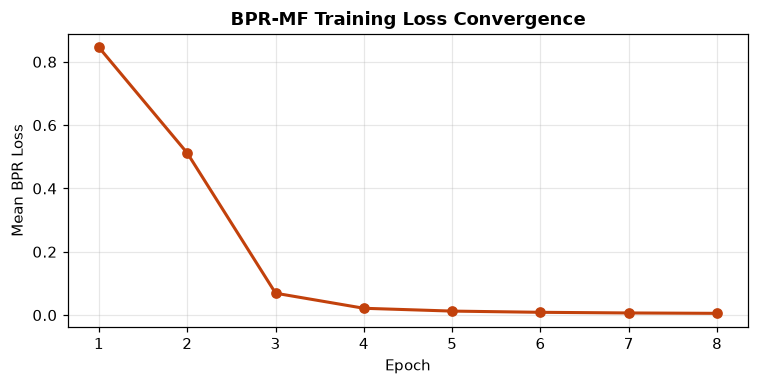

In [2]:
model.eval()
hr_l, ndcg_l, mrr_l = [], [], []
with torch.no_grad():
    for _, row in pipeline.test_df.iterrows():
        u_idx = pipeline.user2idx[row["user_id"]]
        pos_idx = pipeline.item2idx[row["article_id"]]
        user_pos = pipeline.user_positive_items[u_idx]
        cands = [pos_idx]
        while len(cands) < 100:
            c = random.randint(0, pipeline.num_items - 1)
            if c not in user_pos and c not in cands:
                cands.append(c)
        u_t = torch.tensor([u_idx] * 100, dtype=torch.long)
        c_t = torch.tensor(cands, dtype=torch.long)
        scores = (model.user_embeddings(u_t) * model.item_embeddings(c_t)).sum(dim=1).numpy()
        ranked = [cands[i] for i in np.argsort(-scores)]
        hr_l.append(hit_rate_at_k(pos_idx, ranked, k=10))
        ndcg_l.append(ndcg_at_k(pos_idx, ranked, k=10))
        mrr_l.append(mrr(pos_idx, ranked))

print(f"BPR-MF Test Results | HR@10 = {np.mean(hr_l):.4f} | NDCG@10 = {np.mean(ndcg_l):.4f} | MRR = {np.mean(mrr_l):.4f}")
plt.figure(figsize=(7, 3.6))
plt.plot(range(1, len(loss_hist)+1), loss_hist, "o-", color="#c2410c", lw=2)
plt.title("BPR-MF Training Loss Convergence", fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Mean BPR Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()